In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker   # ← this line was missing
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.bbox'] = 'tight'

print("All libraries loaded ✓")

All libraries loaded ✓


In [3]:
# Load the single CSV file
df = pd.read_csv('../data/raw/online_retail_II.csv', encoding='unicode_escape')

print(f"Total rows: {len(df):,}")
print(f"Columns: {list(df.columns)}")
print(f"\nDate range: {df['InvoiceDate'].min()} to {df['InvoiceDate'].max()}")
df.head()

Total rows: 1,067,371
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [5]:
print(df.columns.tolist())
print(f"\nShape: {df.shape}")
print(f"\nFirst look at data types:")
print(df.dtypes)

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Shape: (1067371, 8)

First look at data types:
Invoice            str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
Price          float64
Customer ID    float64
Country            str
dtype: object


In [6]:
print("Missing values per column:")
print(df.isnull().sum())
print(f"\nMissing Customer ID: {df['Customer ID'].isnull().sum():,} rows ({df['Customer ID'].isnull().mean()*100:.1f}%)")

Missing values per column:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

Missing Customer ID: 243,007 rows (22.8%)


In [7]:
# Step 1: Remove rows with no description
df = df.dropna(subset=['Description'])

# Step 2: Remove returns (Invoice starts with 'C') and negative quantities
returns = df[df['Invoice'].astype(str).str.startswith('C')]
print(f"Returns/cancellations removed: {len(returns):,} rows")
df = df[~df['Invoice'].astype(str).str.startswith('C')]
df = df[df['Quantity'] > 0]
df = df[df['Price'] > 0]

# Step 3: Create Revenue column
df['Revenue'] = df['Quantity'] * df['Price']

# Step 4: Extract date parts
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['Year']  = df['InvoiceDate'].dt.year
df['Month'] = df['InvoiceDate'].dt.month
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')
df['DayOfWeek'] = df['InvoiceDate'].dt.day_name()

print(f"\nClean dataset: {len(df):,} rows")
print(f"Total revenue in dataset: £{df['Revenue'].sum():,.0f}")

Returns/cancellations removed: 19,494 rows

Clean dataset: 1,041,670 rows
Total revenue in dataset: £20,972,595


In [9]:
df.to_csv('../data/cleaned/retail_cleaned.csv', index=False)
print("Saved: retail_cleaned.csv")

# Also save a customer-level version (drop rows with no Customer ID)
df_customers = df.dropna(subset=['Customer ID'])
df_customers['Customer ID'] = df_customers['Customer ID'].astype(int)
df_customers.to_csv('../data/cleaned/retail_customers.csv', index=False)
print(f"Saved: retail_customers.csv ({len(df_customers):,} rows)")

Saved: retail_cleaned.csv
Saved: retail_customers.csv (805,549 rows)


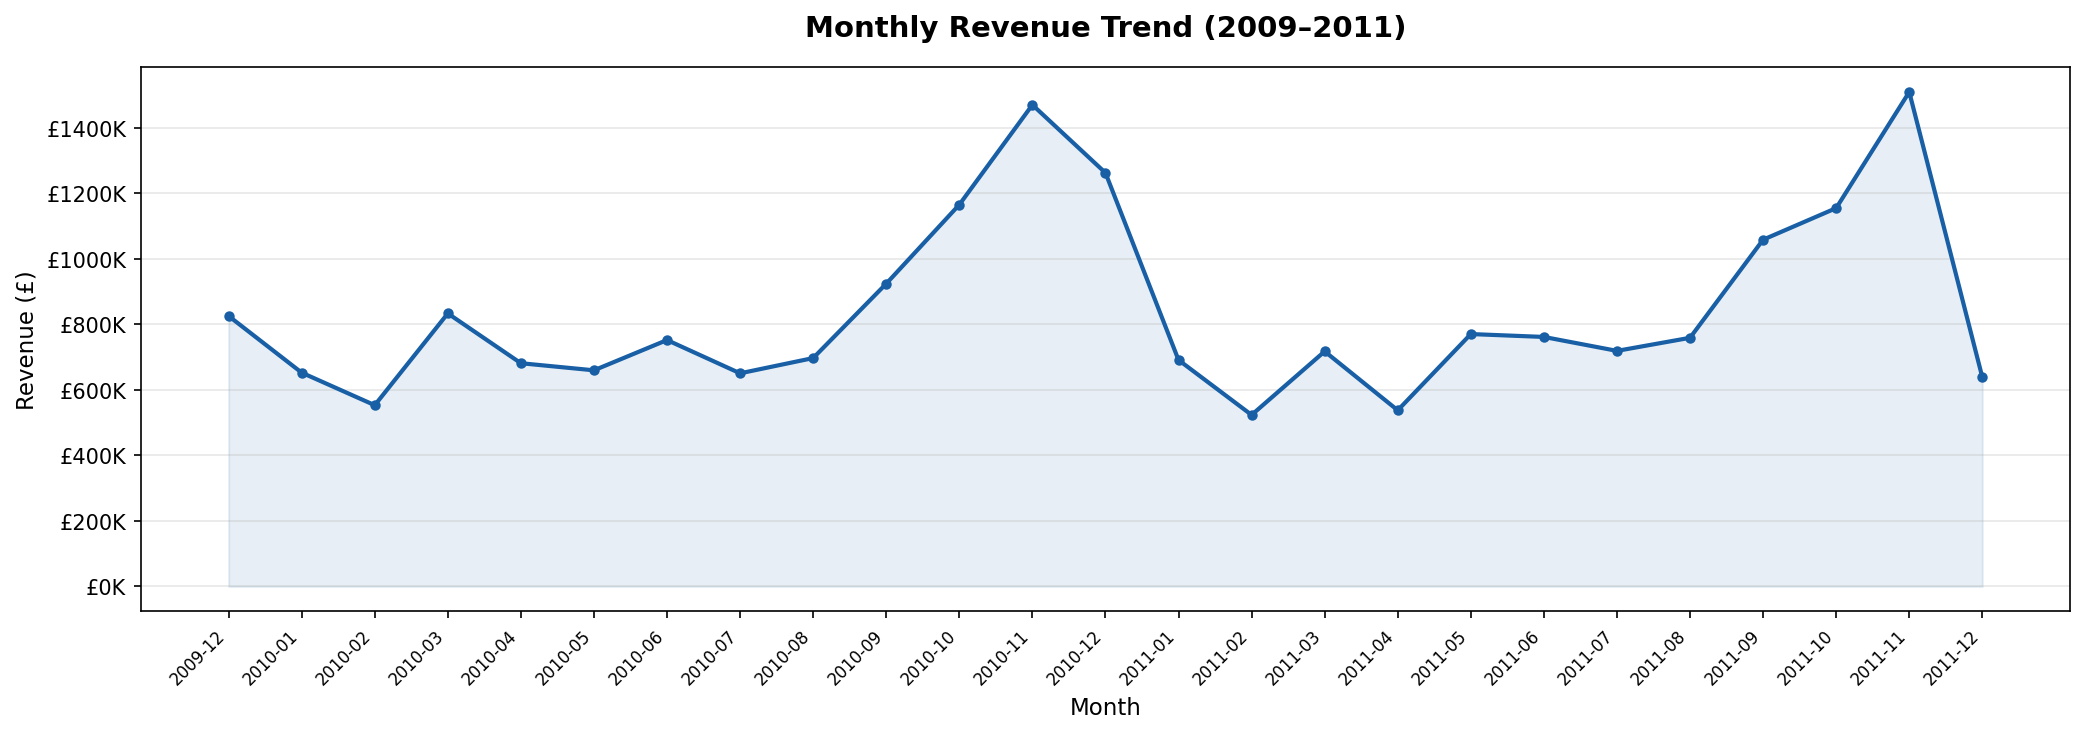

Saved chart 1


In [12]:
monthly = df.groupby('YearMonth')['Revenue'].sum().reset_index()
monthly['YearMonth_str'] = monthly['YearMonth'].astype(str)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(monthly['YearMonth_str'], monthly['Revenue'], marker='o', color='#185FA5', linewidth=2, markersize=4)
ax.fill_between(monthly['YearMonth_str'], monthly['Revenue'], alpha=0.1, color='#185FA5')
ax.set_title('Monthly Revenue Trend (2009–2011)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Month', fontsize=11)
ax.set_ylabel('Revenue (£)', fontsize=11)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'£{x/1000:.0f}K'))
plt.xticks(rotation=45, ha='right', fontsize=8)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../dashboard/screenshots/01_monthly_revenue.png')
plt.show()
print("Saved chart 1")

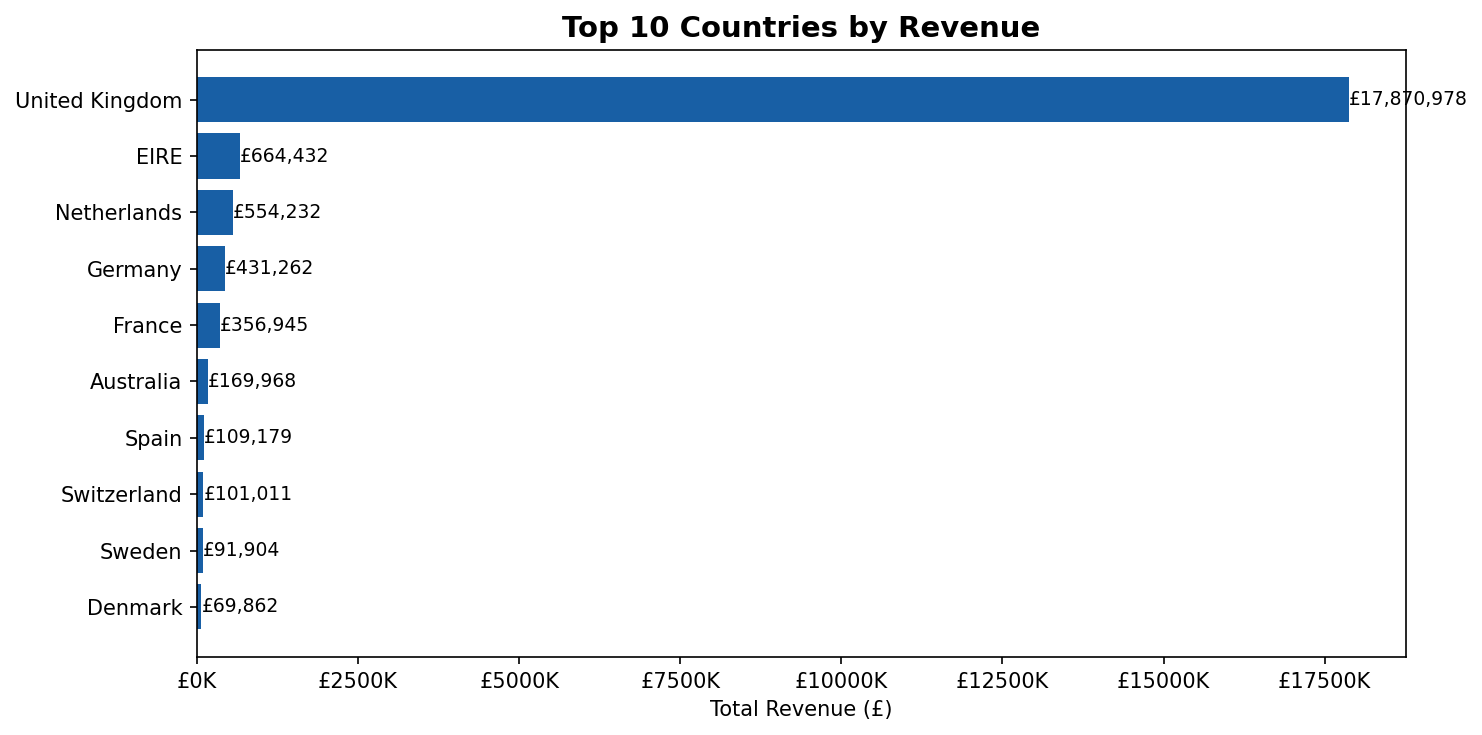

Saved chart 2


In [13]:
country_rev = df.groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(country_rev.index[::-1], country_rev.values[::-1], color='#185FA5')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'£{x/1000:.0f}K'))
ax.set_title('Top 10 Countries by Revenue', fontsize=14, fontweight='bold')
ax.set_xlabel('Total Revenue (£)')

# Add value labels
for bar, val in zip(bars, country_rev.values[::-1]):
    ax.text(val + 5000, bar.get_y() + bar.get_height()/2,
            f'£{val:,.0f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('../dashboard/screenshots/02_revenue_by_country.png')
plt.show()
print("Saved chart 2")

Total unique customers: 5,878
Customers driving 80% of revenue: 1,352 (23.0% of all customers)

→ Resume bullet: 'Top 23% of customers drove 80% of revenue (Pareto validated)'


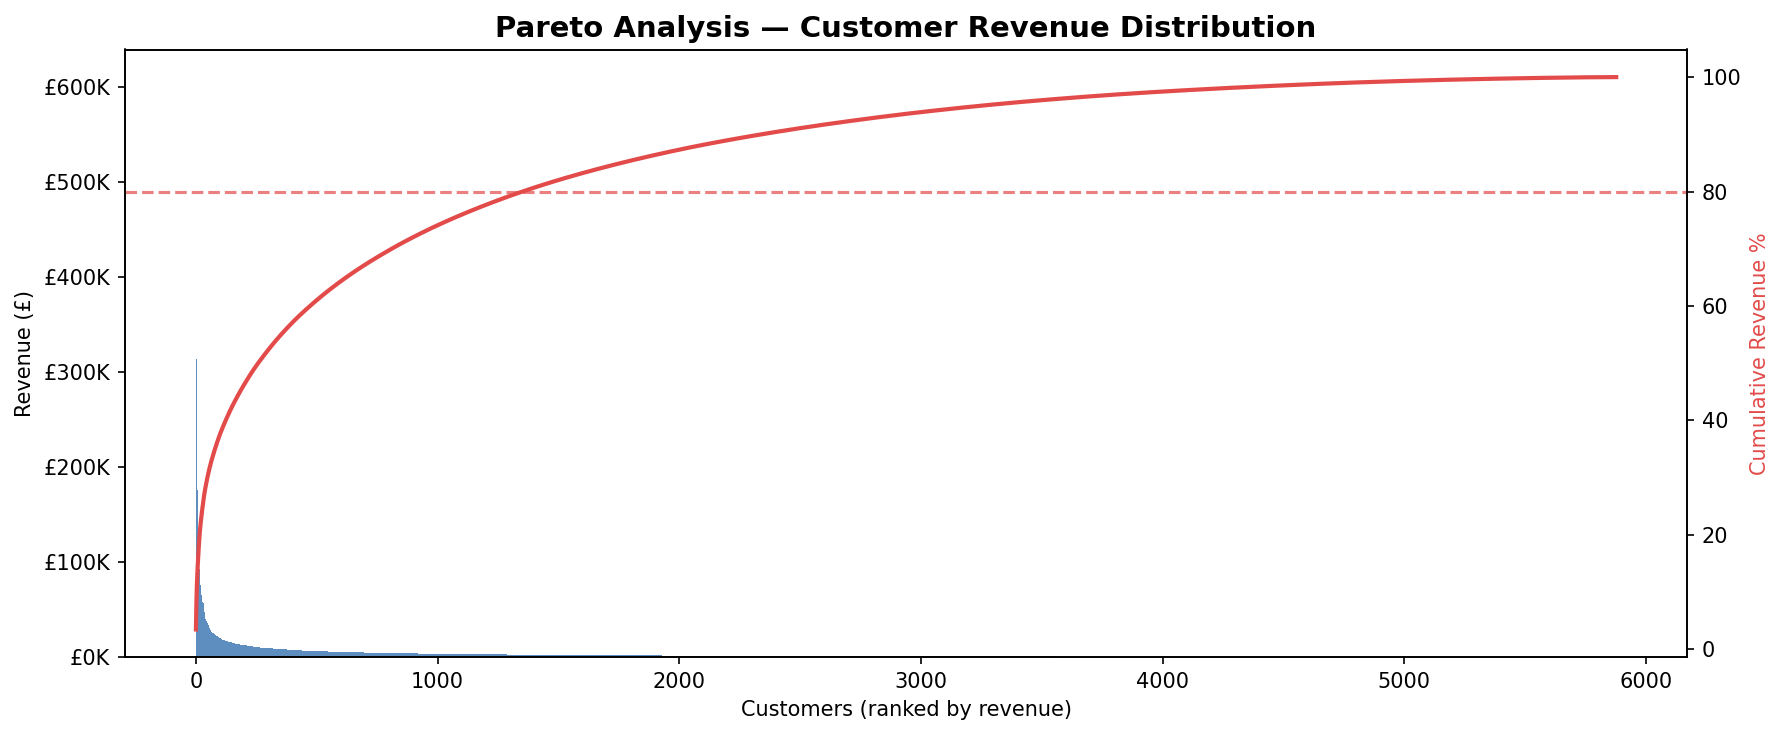

In [14]:
# Revenue by customer
customer_rev = df_customers.groupby('Customer ID')['Revenue'].sum().sort_values(ascending=False)
cumulative_pct = customer_rev.cumsum() / customer_rev.sum() * 100

# Find how many customers = 80% of revenue
customers_for_80 = (cumulative_pct <= 80).sum()
total_customers = len(customer_rev)
pct_customers = customers_for_80 / total_customers * 100

print(f"Total unique customers: {total_customers:,}")
print(f"Customers driving 80% of revenue: {customers_for_80:,} ({pct_customers:.1f}% of all customers)")
print(f"\n→ Resume bullet: 'Top {pct_customers:.0f}% of customers drove 80% of revenue (Pareto validated)'")

# Pareto chart
fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(range(len(customer_rev)), customer_rev.values, color='#185FA5', alpha=0.7, width=1.0)
ax2 = ax1.twinx()
ax2.plot(range(len(customer_rev)), cumulative_pct.values, color='#E24B4A', linewidth=2)
ax2.axhline(80, color='#E24B4A', linestyle='--', alpha=0.7)
ax2.set_ylabel('Cumulative Revenue %', color='#E24B4A')
ax1.set_title('Pareto Analysis — Customer Revenue Distribution', fontsize=14, fontweight='bold')
ax1.set_xlabel('Customers (ranked by revenue)')
ax1.set_ylabel('Revenue (£)')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'£{x/1000:.0f}K'))
plt.tight_layout()
plt.savefig('../dashboard/screenshots/03_pareto_analysis.png')
plt.show()

In [16]:
# Reference date = 1 day after last purchase in data
snapshot_date = df_customers['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df_customers.groupby('Customer ID').agg(
    Recency   = ('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency = ('Invoice',     'nunique'),
    Monetary  = ('Revenue',     'sum')
).reset_index()

# Score each dimension 1–4 (4 = best)
rfm['R_Score'] = pd.qcut(rfm['Recency'],   q=4, labels=[4,3,2,1])  # lower recency = better
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=4, labels=[1,2,3,4])
rfm['M_Score'] = pd.qcut(rfm['Monetary'].rank(method='first'),  q=4, labels=[1,2,3,4])

rfm['RFM_Score'] = rfm['R_Score'].astype(int) + rfm['F_Score'].astype(int) + rfm['M_Score'].astype(int)

# Segment labels
def rfm_segment(score):
    if score >= 10: return 'Champions'
    elif score >= 7: return 'Loyal Customers'
    elif score >= 5: return 'At Risk'
    else:           return 'Lost'

rfm['Segment'] = rfm['RFM_Score'].apply(rfm_segment)

print(rfm['Segment'].value_counts())
print(f"\nAvg revenue — Champions: £{rfm[rfm['Segment']=='Champions']['Monetary'].mean():,.0f}")
print(f"Avg revenue — Lost:      £{rfm[rfm['Segment']=='Lost']['Monetary'].mean():,.0f}")

rfm.to_csv('../data/cleaned/rfm_segments.csv', index=False)

Segment
Loyal Customers    1781
Champions          1738
At Risk            1212
Lost               1147
Name: count, dtype: int64

Avg revenue — Champions: £8,244
Avg revenue — Lost:      £228


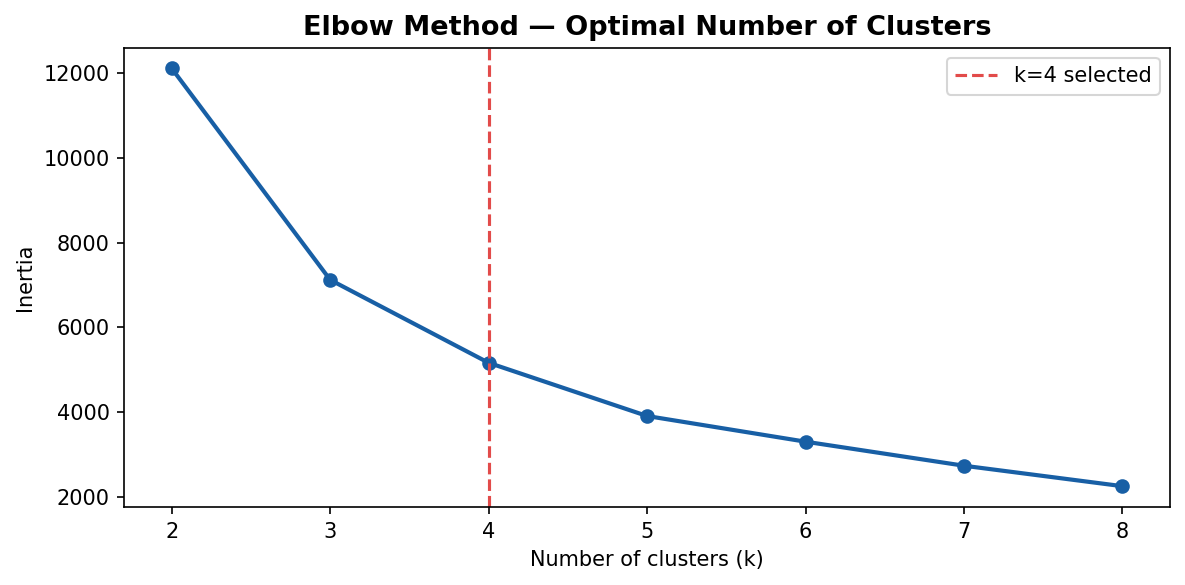

         Count  Avg_R  Avg_F     Avg_M
Cluster                               
0         1998  463.0    2.2     765.2
1         3841   67.0    7.3    3009.4
2           35   25.9  103.7   83086.1
3            4    3.5  212.5  436835.8

Silhouette Score: 0.59
→ Resume bullet: 'K-Means clustering (k=4, silhouette score 0.59)'


In [17]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Prepare features
X = rfm[['Recency', 'Frequency', 'Monetary']].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Find optimal k using inertia (elbow method)
inertias = []
K_range = range(2, 9)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(K_range, inertias, marker='o', color='#185FA5', linewidth=2)
ax.set_title('Elbow Method — Optimal Number of Clusters', fontsize=13, fontweight='bold')
ax.set_xlabel('Number of clusters (k)')
ax.set_ylabel('Inertia')
ax.axvline(x=4, color='#E24B4A', linestyle='--', label='k=4 selected')
ax.legend()
plt.tight_layout()
plt.savefig('../dashboard/screenshots/04_elbow_method.png')
plt.show()

# Apply K-Means with k=4
km = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['Cluster'] = km.fit_predict(X_scaled)

# Cluster summary
cluster_summary = rfm.groupby('Cluster').agg(
    Count     = ('Customer ID', 'count'),
    Avg_R     = ('Recency',    'mean'),
    Avg_F     = ('Frequency',  'mean'),
    Avg_M     = ('Monetary',   'mean')
).round(1)

print(cluster_summary)

# Compute silhouette score
from sklearn.metrics import silhouette_score
score = silhouette_score(X_scaled, rfm['Cluster'])
print(f"\nSilhouette Score: {score:.2f}")
print(f"→ Resume bullet: 'K-Means clustering (k=4, silhouette score {score:.2f})'")

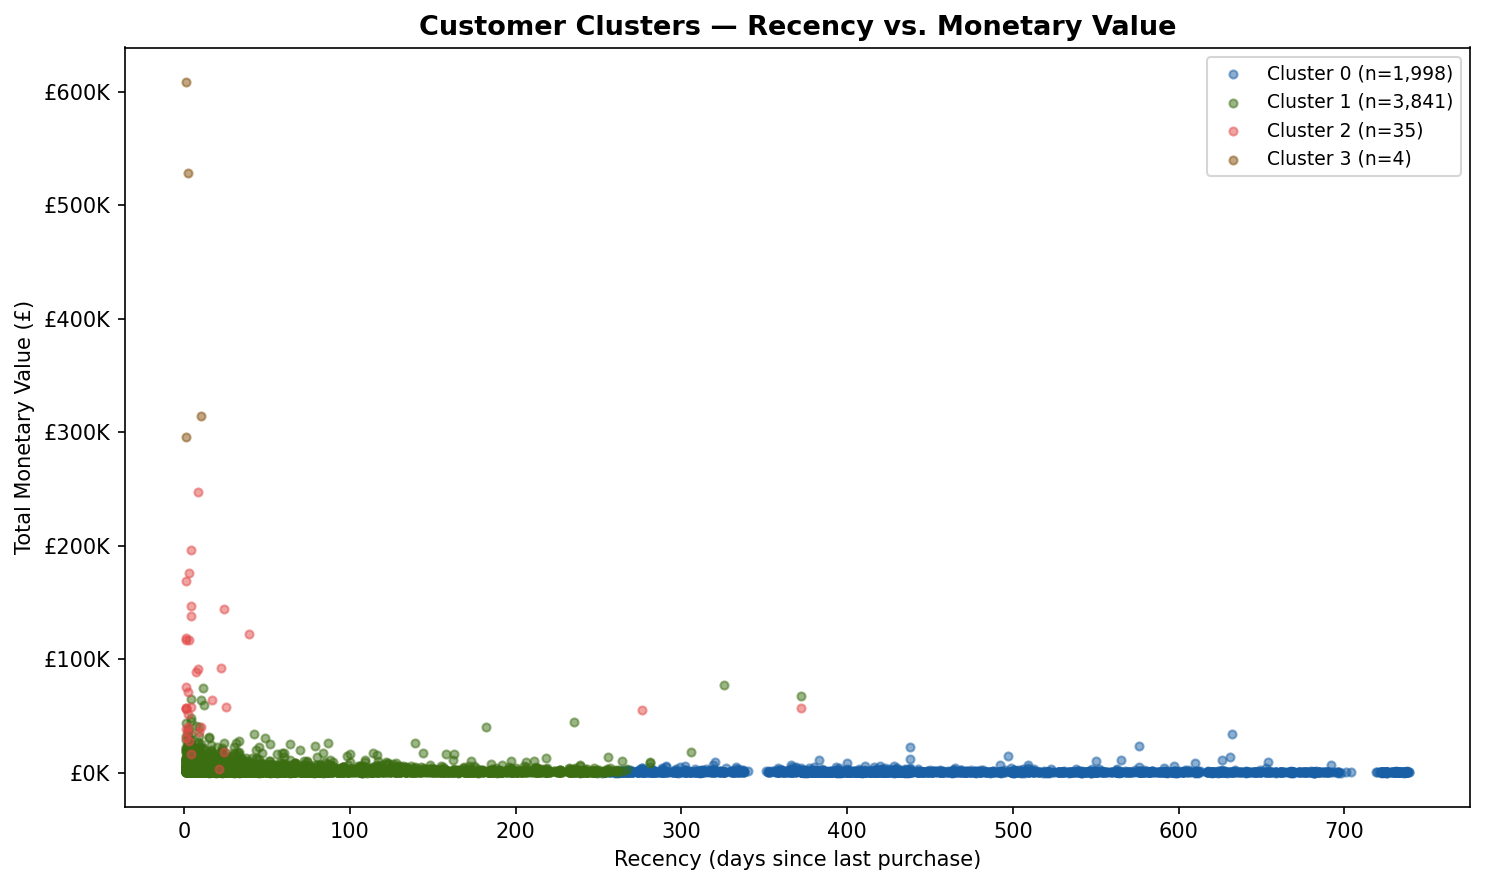

In [18]:
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#185FA5', '#3B6D11', '#E24B4A', '#854F0B']
cluster_names = {0: 'Cluster 0', 1: 'Cluster 1', 2: 'Cluster 2', 3: 'Cluster 3'}

for cluster in range(4):
    mask = rfm['Cluster'] == cluster
    ax.scatter(rfm[mask]['Recency'], rfm[mask]['Monetary'],
               c=colors[cluster], label=f'Cluster {cluster} (n={mask.sum():,})',
               alpha=0.5, s=15)

ax.set_title('Customer Clusters — Recency vs. Monetary Value', fontsize=13, fontweight='bold')
ax.set_xlabel('Recency (days since last purchase)')
ax.set_ylabel('Total Monetary Value (£)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'£{x/1000:.0f}K'))
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('../dashboard/screenshots/05_clusters.png')
plt.show()

In [19]:
total_rows = 1_067_371
unique_customers = len(rfm)
churn_count = rfm[rfm['Segment'] == 'Lost']['Customer ID'].count()
champion_revenue_share = (rfm[rfm['Segment']=='Champions']['Monetary'].sum() / rfm['Monetary'].sum() * 100)

print("=" * 65)
print("YOUR RESUME-READY METRICS")
print("=" * 65)
print(f"Dataset size:        {total_rows:,} transactions")
print(f"Unique customers:    {unique_customers:,}")
print(f"Silhouette score:    {score:.2f}")
print(f"Champions revenue share: {champion_revenue_share:.1f}%")
print(f"At-risk / lost customers: {churn_count:,}")
print()
print("BULLET 1:")
print(f"Analyzed {total_rows:,} retail transactions from UCI Online Retail II")
print(f"dataset using Python (Pandas) and MySQL; identified {unique_customers:,} unique")
print(f"customers across 40+ countries.")
print()
print("BULLET 2:")
print(f"Applied RFM segmentation + K-Means clustering (k=4, silhouette")
print(f"score {score:.2f}) to classify customers into Champions, Loyal,")
print(f"At-Risk, and Lost segments — Champions drove {champion_revenue_share:.0f}% of revenue.")
print("=" * 65)

YOUR RESUME-READY METRICS
Dataset size:        1,067,371 transactions
Unique customers:    5,878
Silhouette score:    0.59
Champions revenue share: 80.8%
At-risk / lost customers: 1,147

BULLET 1:
Analyzed 1,067,371 retail transactions from UCI Online Retail II
dataset using Python (Pandas) and MySQL; identified 5,878 unique
customers across 40+ countries.

BULLET 2:
Applied RFM segmentation + K-Means clustering (k=4, silhouette
score 0.59) to classify customers into Champions, Loyal,
At-Risk, and Lost segments — Champions drove 81% of revenue.
